## Experiment 6: Data Aggregation

**Aim:** Data Aggregation.

**Objective:** To analyze and visualize retail sales data by aggregating and comparing sales across regions and product categories, and to identify the top-performing regions.

In [1]:
# A52 Dipanshu Ambilkar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Step 1: Import the Retail Sales dataset
df = pd.read_csv("retail.csv", parse_dates=["date"])
print("Shape:", df.shape)
df.head()

Shape: (400, 5)


,date,region,category,quantity,amount
0,2026-04-10,South,Grocery,6,597.37
1,2026-04-29,West,Electronics,5,2115.81
2,2026-05-25,South,Grocery,3,4366.17
3,2026-03-15,East,Grocery,1,1099.17
4,2026-01-09,South,Electronics,7,1825.91


In [3]:
# Step 2: Explore the structure and content of the dataset
df.info()
print()
print("Regions:", df["region"].unique())
print("Categories:", df["category"].unique())

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      400 non-null    datetime64[us]
 1   region    400 non-null    str           
 2   category  400 non-null    str           
 3   quantity  400 non-null    int64         
 4   amount    400 non-null    float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 15.8 KB

Regions: <StringArray>
['South', 'West', 'East', 'North']
Length: 4, dtype: str
Categories: <StringArray>
['Grocery', 'Electronics', 'Furniture', 'Clothing']
Length: 4, dtype: str


In [4]:
# Step 3: Aggregate total sales by region
by_region = df.groupby("region")["amount"].sum().sort_values(ascending=False)
print("Total sales by region:")
print(by_region)

Total sales by region:
region
East     302415.93
South    277106.73
North    238128.91
West     214866.47
Name: amount, dtype: float64


In [5]:
# Identify the top-performing region
print("Top-performing region:", by_region.index[0])
print("Top region sales:", by_region.iloc[0])

Top-performing region: East
Top region sales: 302415.93


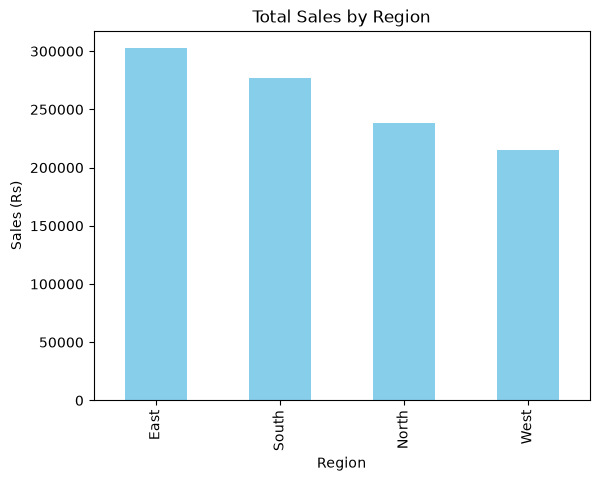

In [6]:
# Step 4: Bar plot of total sales by region
by_region.plot(kind="bar", color="skyblue")
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales (Rs)")
plt.show()

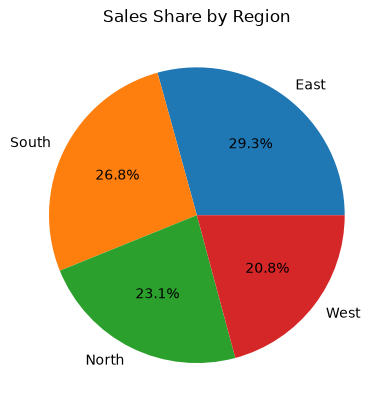

In [7]:
# Pie chart of sales share by region
by_region.plot(kind="pie", autopct="%1.1f%%")
plt.title("Sales Share by Region")
plt.ylabel("")
plt.show()

In [8]:
# Aggregate sales by region and product category together
by_both = df.groupby(["region", "category"])["amount"].sum().unstack()
print("Total sales by region and category:")
print(by_both)

Total sales by region and category:
category  Clothing  Electronics  Furniture   Grocery
region                                              
East      69210.35     92355.88   64309.44  76540.26
North     70766.43     68569.85   42383.33  56409.30
South     56336.63     71520.16   70409.72  78840.22
West      42871.62     62501.51   75803.58  33689.76


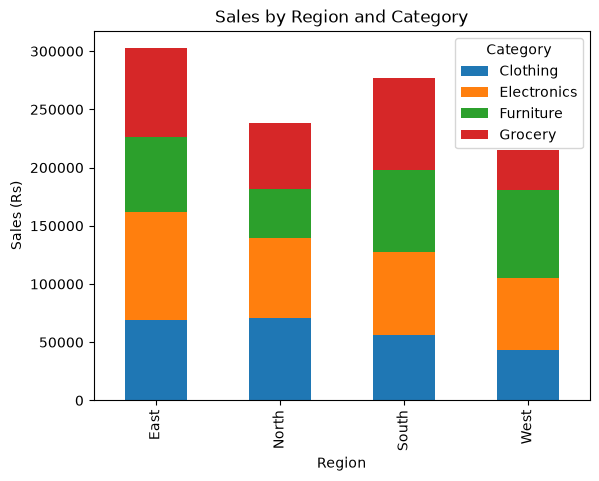

In [9]:
# Stacked bar plot of sales by region and category
by_both.plot(kind="bar", stacked=True)
plt.title("Sales by Region and Category")
plt.xlabel("Region")
plt.ylabel("Sales (Rs)")
plt.legend(title="Category")
plt.show()

In [10]:
# Total sales by product category
by_category = df.groupby("category")["amount"].sum().sort_values(ascending=False)
print("Total sales by category:")
print(by_category)
print("Top-selling category:", by_category.index[0])

Total sales by category:
category
Electronics    294947.40
Furniture      252906.07
Grocery        245479.54
Clothing       239185.03
Name: amount, dtype: float64
Top-selling category: Electronics


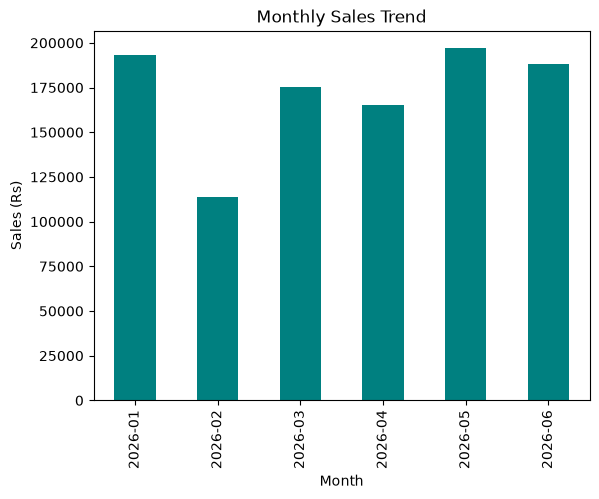

In [11]:
# Monthly sales trend
df["month"] = df["date"].dt.to_period("M").astype(str)
monthly = df.groupby("month")["amount"].sum()
monthly.plot(kind="bar", color="teal")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (Rs)")
plt.show()

**Conclusion:** In this way we have implemented data aggregation, analyzed the sales performance of the retail company by region and identified the top-performing regions. We also identified the top-selling product categories.